In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/CATS/images (1).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/CATS/images (2).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/DOGS/download (4).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/DOGS/images.jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/ELEPHANTS/images (1).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/ELEPHANTS/images (2).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/LIONS/download (5).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/LIONS/images (3).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/TIGERS/download (7).jpg
/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal det

In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import os

DATA_DIR = "/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model"

print("Dataset exists:", os.path.exists(DATA_DIR))
print("Animal folders:", os.listdir(DATA_DIR))

for folder in os.listdir(DATA_DIR):
    folder_path = os.path.join(DATA_DIR, folder)
    if os.path.isdir(folder_path):
        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(folder, "=", len(images), "images")

Dataset exists: True
Animal folders: ['CATS', 'DOGS', 'ELEPHANTS', 'LIONS', 'TIGERS']
CATS = 2 images
DOGS = 2 images
ELEPHANTS = 2 images
LIONS = 2 images
TIGERS = 2 images


IMMAGE PREPARE KRNI HA 

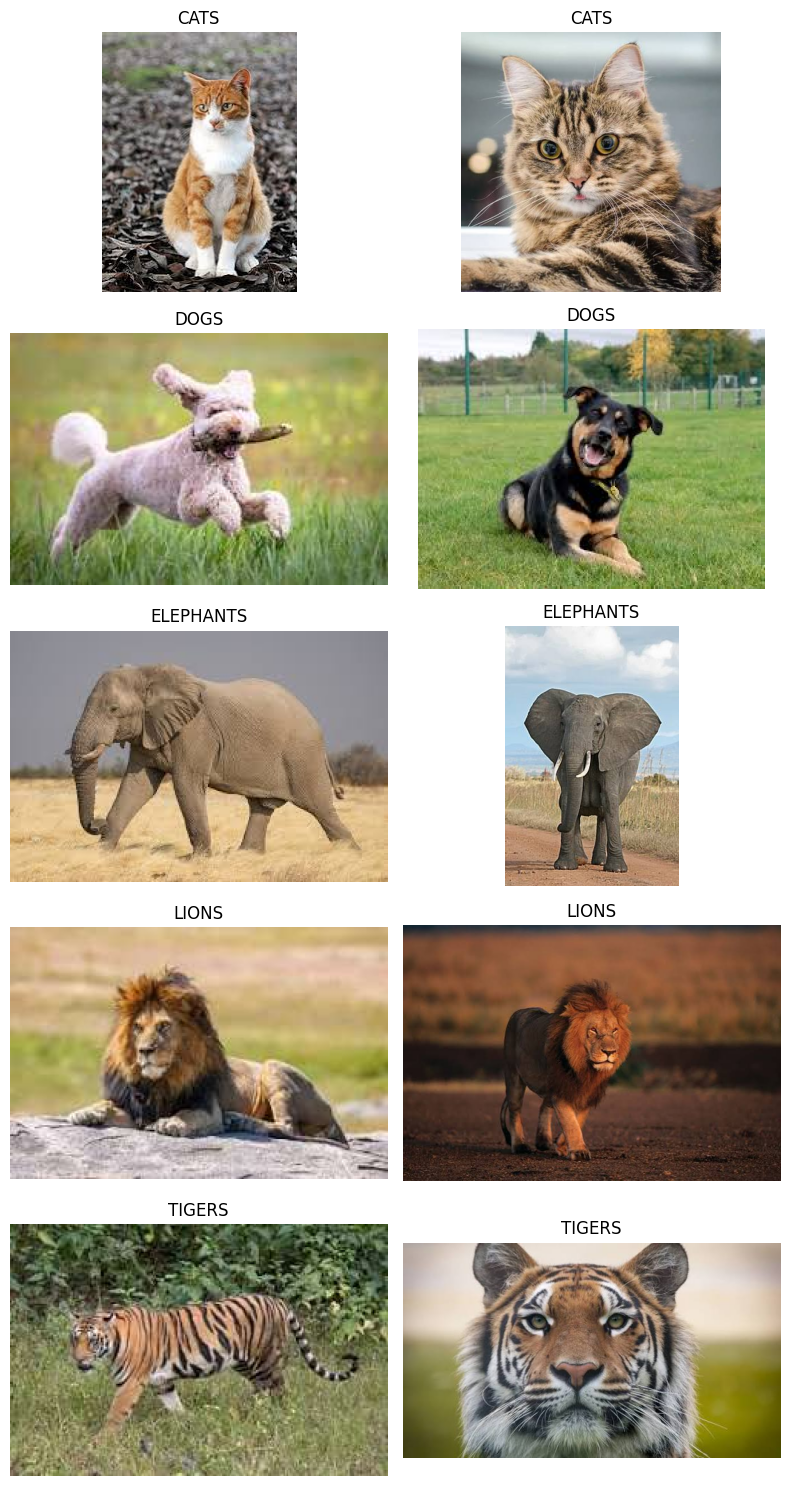

In [15]:
import os
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model"

fig, axes = plt.subplots(5, 2, figsize=(8, 15))

for row, folder in enumerate(
    ["CATS", "DOGS", "ELEPHANTS", "LIONS", "TIGERS"]
):
    folder_path = os.path.join(DATA_DIR, folder)
    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for col in range(2):
        ax = axes[row, col]

        if col < len(images):
            img_path = os.path.join(folder_path, images[col])
            img = Image.open(img_path).convert("RGB")
            ax.imshow(img)
            ax.set_title(folder)
        else:
            ax.text(0.5, 0.5, "No image", ha="center")

        ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = "/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model"

IMG_SIZE = (224, 224)
BATCH_SIZE = 2

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

class_names = train_ds.class_names
print("Animals:", class_names)

base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = keras.Sequential([
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_ds, epochs=10)

model.save("/kaggle/working/animal_model.keras")

print("AI MODEL READY!")

Found 10 files belonging to 5 classes.
Animals: ['CATS', 'DOGS', 'ELEPHANTS', 'LIONS', 'TIGERS']


2026-10-23 06:55:27.296295: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.1000 - loss: 1.7912   
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6000 - loss: 1.1382
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 1.0000 - loss: 0.7106
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 1.0000 - loss: 0.3913
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 0.2618
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 1.0000 - loss: 0.1471
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 1.0000 - loss: 0.1013
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 1.0000 - loss: 0.0917
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 1.0000 - loss: 0.0853
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 1.0000 - loss: 0.0584
AI MODEL READY!


In [17]:

import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

# Apne dataset ke CATS folder se ek image test karein
IMAGE_FOLDER = "/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model/CATS"

image_files = [
    os.path.join(IMAGE_FOLDER, f)
    for f in os.listdir(IMAGE_FOLDER)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

if image_files:
    image_path = image_files[0]

    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)
    index = np.argmax(predictions[0])

    print("Detected Animal:", class_names[index])
    print("Confidence:", round(float(predictions[0][index]) * 100, 2), "%")
else:
    print("Image nahi mili. Folder ka path check karein.")

Detected Animal: CATS
Confidence: 98.06 %



Testing Animal Folder: CATS
Image: images (1).jpg
AI Prediction: CATS
Confidence: 98.06 %


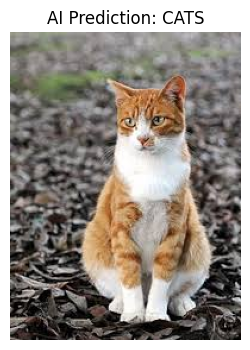

Image: images (2).jpg
AI Prediction: CATS
Confidence: 95.62 %


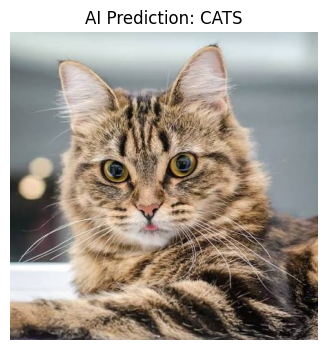


Testing Animal Folder: DOGS
Image: download (4).jpg
AI Prediction: DOGS
Confidence: 91.68 %


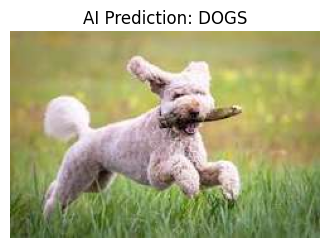

Image: images.jpg
AI Prediction: DOGS
Confidence: 95.51 %


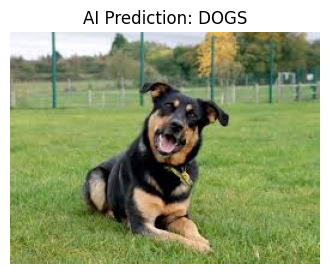


Testing Animal Folder: ELEPHANTS
Image: images (1).jpg
AI Prediction: ELEPHANTS
Confidence: 92.37 %


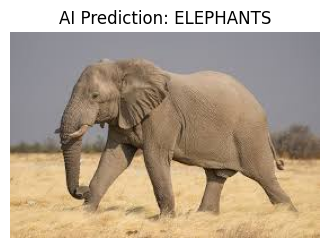

Image: images (2).jpg
AI Prediction: ELEPHANTS
Confidence: 98.05 %


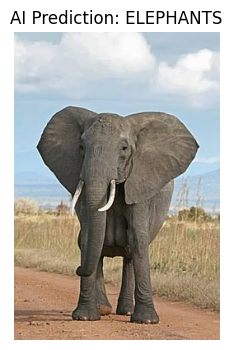


Testing Animal Folder: LIONS
Image: download (5).jpg
AI Prediction: LIONS
Confidence: 93.95 %


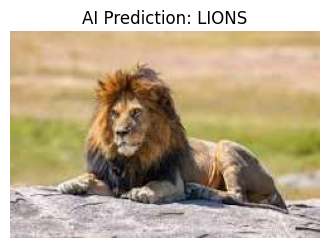

Image: images (3).jpg
AI Prediction: LIONS
Confidence: 95.6 %


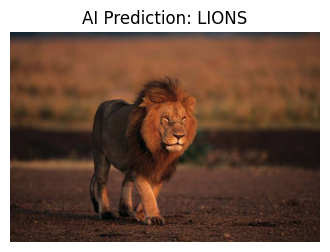


Testing Animal Folder: TIGERS
Image: download (7).jpg
AI Prediction: TIGERS
Confidence: 96.58 %


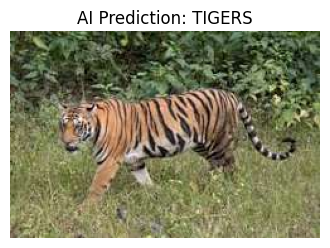

Image: images (9).jpg
AI Prediction: TIGERS
Confidence: 94.45 %


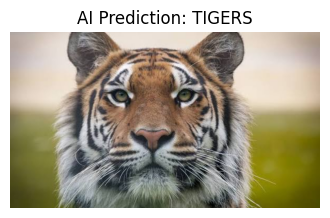

In [18]:

import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

DATA_DIR = "/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model"

animals = ["CATS", "DOGS", "ELEPHANTS", "LIONS", "TIGERS"]

for animal in animals:
    folder = os.path.join(DATA_DIR, animal)

    image_files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    print("\n" + "=" * 35)
    print("Testing Animal Folder:", animal)

    if not image_files:
        print("No images found!")
        continue

    for image_path in image_files:
        img = load_img(image_path, target_size=(224, 224))
        img_array = img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        predictions = model.predict(img_array, verbose=0)
        index = np.argmax(predictions[0])

        print("Image:", os.path.basename(image_path))
        print("AI Prediction:", class_names[index])
        print("Confidence:", round(float(predictions[0][index]) * 100, 2), "%")

        plt.figure(figsize=(4, 4))
        plt.imshow(load_img(image_path))
        plt.title("AI Prediction: " + class_names[index])
        plt.axis("off")
        plt.show()


In [20]:

import os

model_path = "/kaggle/working/animal_model.keras"

if os.path.exists(model_path):
    print("Model found!")
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model not found. Please run the training code again.")


Model found!
File size: 9.25 MB


In [21]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

DATA_DIR = "/kaggle/input/datasets/sarbulandhussain/animal-detction/Animal detection AI model"

# Load all images
IMG_SIZE = (224, 224)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=2,
    shuffle=False
)

class_names = test_ds.class_names

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict animals
predictions = model.predict(test_ds, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print("\n========== MODEL ACCURACY ==========")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_true, y_pred))


Found 10 files belonging to 5 classes.
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step

========== MODEL ACCURACY ==========
Accuracy: 100.00%

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

        CATS       1.00      1.00      1.00         2
        DOGS       1.00      1.00      1.00         2
   ELEPHANTS       1.00      1.00      1.00         2
       LIONS       1.00      1.00      1.00         2
      TIGERS       1.00      1.00      1.00         2

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10


========== CONFUSION MATRIX ==========
[[2 0 0 0 0]
 [0 2 0 0 0]
 [0 0 2 0 0]
 [0 0 0 2 0]
 [0 0 0 0 2]]
